# Notebook 4: 20-year production forecast of the 10 history-matched cases

**Reads:** `hist_match_output/` (the 10 cases from notebook 3), `hist_match_input/` (the proxy, for the posterior band), `data_after_engineering/` (history, forecast dates), `dataset_ori/09 Template Deliverable.xlsx`.
**Writes:** `forecast_output/` with `10_Final_deliverables.xlsx` (the deliverable), CSVs and figures. Method choices: `forecast_summary.md`.

```
 10 history-matched cases (cumulative gas, oil, water, 1998-2008)
            |
  [1] quarter rates; water-oil ratio; liquid rate
            |
  [2] BACKTEST on 100 simulated cases + the observed field: cut at 2005, 2006, 2007,
      forecast to 2008, compare -> choose method, fit window, WOR anchoring, ensemble
            |
  [3] FORECAST each case 2008-04-01 .. 2028-01-01 (80 quarters); gas = GOR x oil
            |
  [4] alternative start (observed 2008 values) ; uncertainty bands ; field reference
            |
  [5] DELIVERABLE: the 09 template filled (Case 1-10), validated on readback
```

**The forecasting problem.** The simulated cases stop at 2008-01-01. No simulator run exists after it, so the 20-year forecast cannot be learned from data the way the proxy was. Each case is extended with a petroleum-engineering forecast method fitted to its own late history. The methods are chosen by a **backtest**: hide the last 1-3 years of the 100 simulated cases and of the real field, forecast them, and compare with what happened.

**Organiser's instructions** (kick-off slides 26, 30, 31; `instruction/`): forecast field production over the next 20 years; "pick the best 10 forecast cases"; fill the template (Date, gas, oil and water production cumulative, quarterly from 04/01/2008); rock properties are static; no new wells after 2008 (team confirmation).

**Team decisions (15 Oct):** each forecast starts from the case's own 2008 values; the alternative (start from the observed 2008 values) is tested and reported; future water injection is held constant at its last value.

In [1]:
import os, sys, json, time, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import torch

warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_after_engineering").exists())
sys.path.insert(0, str(ROOT / "src"))
import proxy_lib as pl
import forecast_lib as fl

DATA_DIR = ROOT / "data_after_engineering"
HM_IN, HM_OUT = ROOT / "hist_match_input", ROOT / "hist_match_output"
TEMPLATE = ROOT / "dataset_ori" / "09 Template Deliverable.xlsx"
FC_DIR = ROOT / "forecast_output"; FIG_DIR = FC_DIR / "figs"
FC_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(exist_ok=True)
DELIVERABLE = FC_DIR / "10_Final_deliverables.xlsx"
torch.set_num_threads(2)
OIL, GAS, WATER = fl.OIL, fl.GAS, fl.WATER          # model phase order: oil, gas, water

INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE_600, BLUE_450, BLUE_250, ORANGE, AQUA = "#184f95", "#2a78d6", "#86b6ef", "#eb6834", "#1baf7a"
PH_COL = {"oil": BLUE_450, "gas": ORANGE, "water": AQUA}
plt.rcParams.update({"font.family": "sans-serif", "font.size": 9, "figure.facecolor": SURF, "axes.facecolor": SURF,
                     "savefig.facecolor": SURF, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED})


def _ax(ax):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True); ax.tick_params(labelsize=8)
    return ax


def _finish(fig, name, title=None):
    if title:
        fig.suptitle(title, x=0.01, ha="left", color=INK, fontsize=10)
    fig.tight_layout(); fig.savefig(FIG_DIR / f"{name}.png", dpi=130); plt.show()

## 1. Data

* **History** (`history_observed.csv`): cumulative oil, gas and water on the 41 quarterly dates, and the water injection rate.
* **Simulated cases** (`curves_quarterly_cum.npz`): the 100 cases, used for the backtest only.
* **The 10 cases** (`hist_match_output/top10_*`): their 1998-2008 curves (simulator curves for simulated cases, proxy curves for new parameter sets).
* **Forecast dates** (`forecast_dates.csv`): the 80 template dates, 2008-04-01 to 2028-01-01.

Rates are quarter means: (cumulative at a date - cumulative a quarter earlier) / days. The same definition is used for every curve.

In [2]:
D = pl.load_data("cumulative")                    # Y (100, 41, 3) and y_hist in oil, gas, water order
Y_SIM, YH, T = D["Y"], D["y_hist"], D["t_days"]
DATES = pd.DatetimeIndex(D["dates"])
HIST = pd.read_csv(DATA_DIR / "history_observed.csv")
INJ = HIST["water_inj_rate"].to_numpy(float)
INJ_FUTURE = float(INJ[-1])                        # team decision: constant after 2008
FD = pd.read_csv(DATA_DIR / "forecast_dates.csv", parse_dates=["date"])
T_OUT = FD["t_days"].to_numpy(float)
K_END = len(T) - 1                                 # index of 2008-01-01

TOP = pd.read_csv(HM_OUT / "top10_cases_real.csv")
SER = pd.read_csv(HM_OUT / "top10_series_real.csv")
C10 = np.stack([SER[SER["rank"] == r].sort_values("date")[["oil_cum", "gas_cum", "water_cum"]].to_numpy(float)
                for r in TOP["rank"]])            # (10, 41, 3) oil, gas, water
LABELS = [f"Case {r}: " + (f"sim {int(c)}" if s == "simulated" else "new set") for r, s, c in zip(TOP["rank"], TOP["source"], TOP["case_id"])]
assert C10.shape == (10, len(T), 3) and len(T_OUT) == 80
print(f"history to {DATES[-1].date()}; forecast {FD.date.iloc[0].date()} to {FD.date.iloc[-1].date()} ({len(T_OUT)} quarters)")
print(f"water injection: {INJ[4]:,.0f} STB/d (1999) -> {INJ[-1]:,.0f} STB/d (2008); held at {INJ_FUTURE:,.0f} STB/d after 2008")

QH = fl.quarter_rates(YH[None], T)[0]
Q10 = fl.quarter_rates(C10, T)
tab = pd.DataFrame({"case": ["observed"] + LABELS,
                    "oil_rate_2008": np.r_[QH[-1, OIL], Q10[:, -1, OIL]],
                    "water_rate_2008": np.r_[QH[-1, WATER], Q10[:, -1, WATER]],
                    "oil_cum_2008_MM": np.r_[YH[-1, OIL], C10[:, -1, OIL]] / 1e6,
                    "water_cum_2008_MM": np.r_[YH[-1, WATER], C10[:, -1, WATER]] / 1e6})
print("\nRates (last quarter, STB/d) and cumulatives (MMSTB) on 2008-01-01:")
print(tab.round(2).to_string(index=False))

history to 2008-01-01; forecast 2008-04-01 to 2028-01-01 (80 quarters)
water injection: 12,098 STB/d (1999) -> 9,327 STB/d (2008); held at 9,327 STB/d after 2008

Rates (last quarter, STB/d) and cumulatives (MMSTB) on 2008-01-01:
           case  oil_rate_2008  water_rate_2008  oil_cum_2008_MM  water_cum_2008_MM
       observed        5246.80          7782.27            38.38              12.81
  Case 1: sim 6        5955.48          6999.58            38.62              12.54
Case 2: new set        5939.29          7035.22            38.60              12.55
Case 3: new set        5912.75          7029.07            38.59              12.54
Case 4: new set        5920.64          6993.84            38.61              12.53
Case 5: new set        5903.55          6999.09            38.59              12.55
Case 6: new set        5972.94          6982.73            38.64              12.56
 Case 7: sim 97        6015.35          7013.71            38.62              12.58
 Case 8: sim 7

**Reading.** The 10 cases match the observed *cumulatives* within about 1-2 %, but their *rates* in the last quarter differ more: oil is higher and water lower than the field's. This is the same water under-match reported in `hist_mat_summary.md`, now visible at the end of the history, where the forecast starts. Section 5 tests what this means for the forecast.

## 2. Forecast methods

| Code | Method | Oil | Water | Source |
|---|---|---|---|---|
| `elton` | Elton's cumulative families (baseline) | Arps-type cumulative curve fitted to the whole 1998-2008 curve | Gompertz curve fitted to the whole curve | `Elton Model/forecast_pipeline.py` |
| `arps_wor` | Decline curve + water-oil ratio trend | Arps hyperbolic rate decline fitted on the last *n* quarters, b in [0, 1], **modified hyperbolic**: switch to exponential at a terminal decline of 5 %/yr | ln(WOR) linear in cumulative oil, so water = WOR x oil | Arps (1945); Robertson's terminal decline; Wright (1958), Ershaghi & Omoregie (1978) |
| `liq_wor` | Liquid trend + WOR split | Liquid rate with an exponential (non-increasing) trend, split by the WOR trend | Same | Fractional-flow / water-cut extrapolation |
| `crm_wor` | Capacitance-resistance model (tank) + WOR split | Liquid rate from injection: q_L relaxes to G x injection with time constant tau; injection held at its 2008 value | Same | Sayarpour et al. (2007, 2009); CRM + fractional flow (Cao 2014; Oliveira et al. 2021) |

* **Gas** = GOR x oil, with the GOR of the case's last 4 quarters (about 0.3633 in every case and in the field).
* **WOR anchoring** (an option tested in the backtest): `fit` uses the least-squares line; `last` keeps its slope but moves it through the last 2 quarters' WOR, to remove the lag of a line fitted over the whole window.
* **Physical rules.** Cumulatives only increase; the oil decline rate is never negative (no new wells); water cut stays below 1 (WOR > 0); the forecast starts at the case's own 2008 cumulative (continuity).
* **Why not continue the proxy in time.** The proxy maps parameters to the 41 dates it was trained on. There is no training data after 2008, so it cannot forecast. Si Jie's recurrent networks, which can run past 2008, flattened their oil decline after 2010 (`Si Jie's model/summary.md`, limitation 1).

## 3. Backtest: choose the method

**Design.** For each cut-off (2005-01-01, 2006-01-01, 2007-01-01), each method uses only the data up to the cut-off and forecasts to 2008-01-01 (12, 8 and 4 quarters ahead). The forecast is compared with the truth on **all 100 simulated cases** and on **the observed field**. Elton's backtest used one split (fit on quarters 1-25, score 26-41) on the cases only.

**Error measure.** Relative error of the volume produced between the cut-off and 2008-01-01, per phase: (forecast - actual) / actual. Summaries over the 100 cases: the median absolute error and the median signed error (bias).

**Settings searched:** fit window n = 8, 12 or 16 quarters; WOR anchoring `fit` or `last`. Water injection after the cut-off is held at its cut-off value, as in the real forecast.

**Choice.** The score of a setting = mean over the 3 cut-offs of (median |error| oil + median |error| water) / 2 on the cases. The field is reported next to it as a check. The best setting of each method is kept; then the average of the two best methods (an ensemble) is tested the same way.

In [3]:
CUTS = [28, 32, 36]
WINDOWS = [8, 12, 16]
CURVES = np.concatenate([Y_SIM, YH[None]])         # 100 cases + the field (last row)
FIELD = len(CURVES) - 1


def produced_error(dNo, dNw, C, kc):
    truth_o, truth_w = C[K_END, OIL] - C[kc, OIL], C[K_END, WATER] - C[kc, WATER]
    return (dNo[-1] - truth_o) / truth_o * 100, (dNw[-1] - truth_w) / truth_w * 100


def run_setting(method, n, anchor, kc):
    tout = T[kc + 1:]
    E = np.empty((len(CURVES), 2))
    for i, C in enumerate(CURVES):
        E[i] = produced_error(*fl.forecast_case(method, C, T, kc, tout, n, INJ, INJ[kc], wor_anchor=anchor), C, kc)
    return E


t0 = time.time()
rows, ERR = [], {}
for kc in CUTS:
    tout = T[kc + 1:]
    dNo, dNw = fl.forecast_elton(CURVES, T, kc, tout)
    E = np.array([produced_error(dNo[i], dNw[i], CURVES[i], kc) for i in range(len(CURVES))])
    ERR[("elton", 0, "-", kc)] = E
    for m in ("arps_wor", "liq_wor", "crm_wor"):
        for n in WINDOWS:
            for anchor in ("fit", "last"):
                ERR[(m, n, anchor, kc)] = run_setting(m, n, anchor, kc)
for (m, n, anchor, kc), E in ERR.items():
    rows.append({"method": m, "window": n, "wor_anchor": anchor, "cutoff": str(DATES[kc].date()), "horizon_q": K_END - kc,
                 "cases_med_abs_oil_%": np.median(np.abs(E[:FIELD, 0])), "cases_med_abs_water_%": np.median(np.abs(E[:FIELD, 1])),
                 "cases_bias_oil_%": np.median(E[:FIELD, 0]), "cases_bias_water_%": np.median(E[:FIELD, 1]),
                 "field_oil_%": E[FIELD, 0], "field_water_%": E[FIELD, 1]})
BT = pd.DataFrame(rows)
BT.to_csv(FC_DIR / "backtest_all_settings.csv", index=False)
print(f"backtest: {len(ERR)} setting x cut-off runs on {len(CURVES)} curves in {time.time() - t0:.0f} s")

agg = BT.groupby(["method", "window", "wor_anchor"]).agg(
    oil=("cases_med_abs_oil_%", "mean"), water=("cases_med_abs_water_%", "mean"),
    bias_oil=("cases_bias_oil_%", "mean"), bias_water=("cases_bias_water_%", "mean"),
    field_oil=("field_oil_%", lambda x: np.mean(np.abs(x))), field_water=("field_water_%", lambda x: np.mean(np.abs(x)))).reset_index()
agg["score"] = (agg["oil"] + agg["water"]) / 2
agg["field_score"] = (agg["field_oil"] + agg["field_water"]) / 2
BEST = agg.loc[agg.groupby("method")["score"].idxmin()].sort_values("score").reset_index(drop=True)
BEST.to_csv(FC_DIR / "backtest_best_per_method.csv", index=False)
print("\nBest setting of each method (mean over the 3 cut-offs; errors in % of the produced volume):")
print(BEST.round(2).to_string(index=False))

backtest: 57 setting x cut-off runs on 101 curves in 28 s

Best setting of each method (mean over the 3 cut-offs; errors in % of the produced volume):
  method  window wor_anchor   oil  water  bias_oil  bias_water  field_oil  field_water  score  field_score
 crm_wor      12       last  2.80   3.08     -1.89       -2.09       2.60         5.31   2.94         3.95
arps_wor      12       last  4.67   4.26     -3.04       -4.08       2.53         7.29   4.47         4.91
 liq_wor      16        fit  4.85   6.02     -4.15       -2.34       4.14         8.05   5.44         6.09
   elton       0          - 62.30  66.06     62.30      -66.06      61.80        70.21  64.18        66.00


In [4]:
# Ensemble: the average of the two best methods' added volumes, scored the same way
m1, m2 = BEST.iloc[0], BEST.iloc[1]
ens_rows = []
for kc in CUTS:
    E1, E2 = ERR[(m1.method, m1.window, m1.wor_anchor, kc)], ERR[(m2.method, m2.window, m2.wor_anchor, kc)]
    # errors are linear in the forecast volume, so the ensemble error is the mean of the two errors
    E = 0.5 * (E1 + E2)
    ERR[("ensemble", 0, "-", kc)] = E
    ens_rows.append({"cutoff": str(DATES[kc].date()), "oil": np.median(np.abs(E[:FIELD, 0])), "water": np.median(np.abs(E[:FIELD, 1])),
                     "field_oil": abs(E[FIELD, 0]), "field_water": abs(E[FIELD, 1])})
ENS = pd.DataFrame(ens_rows)
ens_score = (ENS["oil"].mean() + ENS["water"].mean()) / 2
print(f"ensemble of {m1.method} (n={m1.window}, {m1.wor_anchor}) and {m2.method} (n={m2.window}, {m2.wor_anchor}): "
      f"score {ens_score:.2f} % against {m1.score:.2f} % for {m1.method} alone")
USE_ENSEMBLE = bool(ens_score < m1.score)
FINAL = [m1, m2] if USE_ENSEMBLE else [m1]
FINAL_NAME = " + ".join(f"{m.method} (n={m.window}, WOR {m.wor_anchor})" for m in FINAL)
print("FINAL forecast method:", FINAL_NAME)

ensemble of crm_wor (n=12, last) and arps_wor (n=12, last): score 3.48 % against 2.94 % for crm_wor alone
FINAL forecast method: crm_wor (n=12, WOR last)


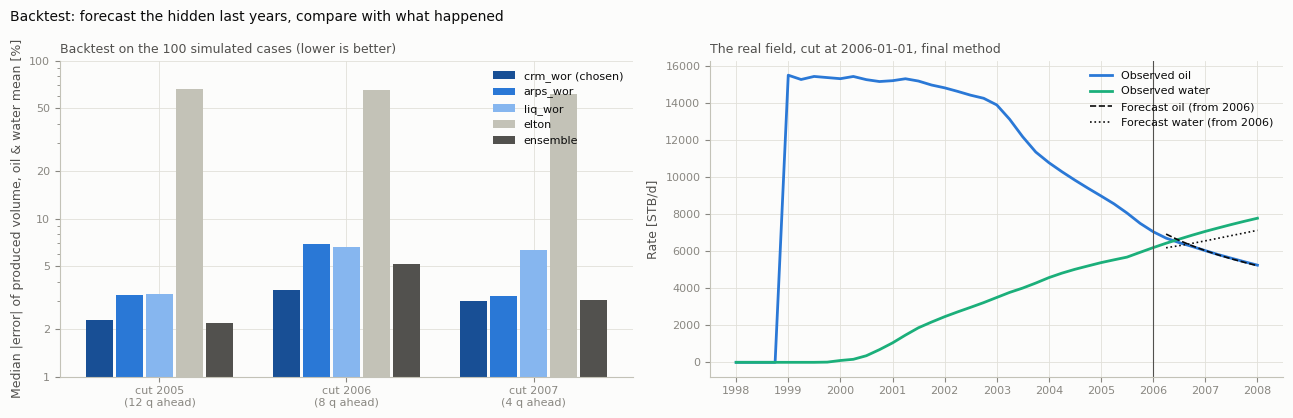

In [5]:
# Figure: backtest errors by method and cut-off, and the field example at the 2006 cut-off
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = _ax(axes[0])
names = list(BEST["method"]) + ["ensemble"]
x = np.arange(len(CUTS))
w = 0.8 / len(names)
for j, nm in enumerate(names):
    if nm == "ensemble":
        vals = [(np.median(np.abs(ERR[("ensemble", 0, "-", kc)][:FIELD, 0])) + np.median(np.abs(ERR[("ensemble", 0, "-", kc)][:FIELD, 1]))) / 2 for kc in CUTS]
    else:
        b = BEST[BEST.method == nm].iloc[0]
        vals = [(np.median(np.abs(ERR[(nm, b.window, b.wor_anchor, kc)][:FIELD, 0])) + np.median(np.abs(ERR[(nm, b.window, b.wor_anchor, kc)][:FIELD, 1]))) / 2 for kc in CUTS]
    col = {"elton": AXIS, "ensemble": INK2}.get(nm, [BLUE_600, BLUE_450, BLUE_250][min(j, 2)])   # BEST is sorted: darkest = best
    ax.bar(x + (j - len(names) / 2 + 0.5) * w, vals, w * 0.92, label=nm + (" (chosen)" if nm == FINAL[0].method and not USE_ENSEMBLE else ""),
           color=col)
ax.set_xticks(x); ax.set_xticklabels([f"cut {DATES[k].year}\n({K_END - k} q ahead)" for k in CUTS])
ax.set_ylabel("Median |error| of produced volume, oil & water mean [%]")
ax.set_yscale("log"); ax.legend(frameon=False, fontsize=8)
ax.set_yticks([1, 2, 5, 10, 20, 50, 100]); ax.set_yticklabels(["1", "2", "5", "10", "20", "50", "100"])
ax.set_title("Backtest on the 100 simulated cases (lower is better)", loc="left", fontsize=9, color=INK2)
ax = _ax(axes[1])
kc = 32
tout = T[kc + 1:]
for ph, j in [("oil", OIL), ("water", WATER)]:
    ax.plot(DATES, QH[:, j], color=PH_COL[ph], lw=2, label=f"observed {ph}")
for m in FINAL:
    dNo, dNw = fl.forecast_case(m.method, YH, T, kc, tout, int(m.window), INJ, INJ[kc], wor_anchor=m.wor_anchor)
    cum_o, cum_w = YH[kc, OIL] + dNo, YH[kc, WATER] + dNw
    q_o = np.diff(np.r_[YH[kc, OIL], cum_o]) / np.diff(np.r_[T[kc], tout])
    q_w = np.diff(np.r_[YH[kc, WATER], cum_w]) / np.diff(np.r_[T[kc], tout])
    ax.plot(DATES[kc + 1:], q_o, color=INK, lw=1.2, ls="--")
    ax.plot(DATES[kc + 1:], q_w, color=INK, lw=1.2, ls=":")
ax.axvline(DATES[kc], color=INK2, lw=0.8)
ax.set_ylabel("Rate [STB/d]")
ax.legend(handles=[Line2D([], [], color=PH_COL["oil"], lw=2, label="Observed oil"), Line2D([], [], color=PH_COL["water"], lw=2, label="Observed water"),
                   Line2D([], [], color=INK, lw=1.2, ls="--", label="Forecast oil (from 2006)"), Line2D([], [], color=INK, lw=1.2, ls=":", label="Forecast water (from 2006)")],
          frameon=False, fontsize=8)
ax.set_title("The real field, cut at 2006-01-01, final method", loc="left", fontsize=9, color=INK2)
_finish(fig, "backtest", "Backtest: forecast the hidden last years, compare with what happened")

## 4. Forecast of the 10 cases (main: each case starts from its own 2008 values)

In [6]:
def forecast_curve(C, anchor_rates=None):
    # Added oil and water after 2008-01-01 at the 80 dates, final method (ensemble = mean of the methods).
    outs = [fl.forecast_case(m.method, C, T, K_END, T_OUT, int(m.window), INJ, INJ_FUTURE,
                             wor_anchor=m.wor_anchor, anchor_rates=anchor_rates) for m in FINAL]
    return np.mean([o[0] for o in outs], axis=0), np.mean([o[1] for o in outs], axis=0)


def build(C, start=None, anchor_rates=None):
    # Full cumulative forecast (80, 3) in oil, gas, water order. start: the 2008 cumulative to add to.
    start = C[K_END] if start is None else start
    dNo, dNw = forecast_curve(C, anchor_rates)
    gor = fl.gor_at_cut(C, T, K_END)
    F = np.empty((len(T_OUT), 3))
    F[:, OIL], F[:, WATER], F[:, GAS] = start[OIL] + dNo, start[WATER] + dNw, start[GAS] + gor * dNo
    return F


FC = np.stack([build(C) for C in C10])                       # (10, 80, 3)
FQ = np.diff(np.concatenate([C10[:, -1:, :], FC], axis=1), axis=1) / np.diff(np.r_[T[-1], T_OUT])[None, :, None]
checks = {
    "cumulatives never decrease": bool((np.diff(np.concatenate([C10[:, -1:, :], FC], axis=1), axis=1) >= -1e-6).all()),
    "oil rate never increases (no new wells)": bool((np.diff(FQ[:, :, OIL], axis=1) <= 1e-6).all()),
    "water cut below 1": bool((FQ[:, :, WATER] / (FQ[:, :, OIL] + FQ[:, :, WATER]) < 1).all()),
    "all values finite and positive": bool(np.isfinite(FC).all() and (FC > 0).all()),
}
for k, v in checks.items():
    print("PASS" if v else "FAIL", "-", k)
SUM = pd.DataFrame({"case": LABELS,
                    "oil_2008_MM": C10[:, -1, OIL] / 1e6, "oil_2028_MM": FC[:, -1, OIL] / 1e6,
                    "water_2008_MM": C10[:, -1, WATER] / 1e6, "water_2028_MM": FC[:, -1, WATER] / 1e6,
                    "gas_2028_MMMSCF": FC[:, -1, GAS] / 1e6,
                    "oil_rate_2028": FQ[:, -1, OIL], "water_cut_2028": FQ[:, -1, WATER] / (FQ[:, -1, OIL] + FQ[:, -1, WATER])})
SUM.to_csv(FC_DIR / "forecast_summary_by_case.csv", index=False)
print("\n" + SUM.round(3).to_string(index=False))

PASS - cumulatives never decrease
PASS - oil rate never increases (no new wells)
PASS - water cut below 1
PASS - all values finite and positive

           case  oil_2008_MM  oil_2028_MM  water_2008_MM  water_2028_MM  gas_2028_MMMSCF  oil_rate_2028  water_cut_2028
  Case 1: sim 6       38.624       61.067         12.537         82.881           22.187       1686.336           0.867
Case 2: new set       38.602       60.861         12.555         83.079           22.108       1666.963           0.869
Case 3: new set       38.588       60.696         12.538         83.061           22.048       1652.057           0.870
Case 4: new set       38.614       60.824         12.529         82.966           22.094       1661.055           0.869
Case 5: new set       38.590       60.705         12.553         83.098           22.051       1651.766           0.870
Case 6: new set       38.637       61.120         12.563         82.975           22.202       1687.508           0.867
 Case 7: sim 97

## 5. Alternative start: the observed 2008 values (tested, team decision 2)

The main forecast continues each case from its own 2008 values. Two alternatives start from the field instead:

* **A1 - observed cumulative:** the same added volumes, put on top of the observed 2008 cumulatives (a shift).
* **A2 - observed start:** the forecast starts from the observed 2008 cumulatives **and** the observed last-quarter oil and water rates; the case only supplies the shape (decline, WOR slope, liquid trend).

In [7]:
OBS_RATES = (QH[-1, OIL], QH[-1, WATER])
FC_A1 = np.stack([build(C, start=YH[-1]) for C in C10])
FC_A2 = np.stack([build(C, start=YH[-1], anchor_rates=OBS_RATES) for C in C10])
rows = []
for nm, F in [("main: own 2008 values", FC), ("A1: observed cumulative", FC_A1), ("A2: observed cumulative + rates", FC_A2)]:
    for j, ph in [(OIL, "oil"), (WATER, "water"), (GAS, "gas")]:
        rows.append({"start": nm, "phase": ph, "P10_2028_MM": np.percentile(F[:, -1, j], 10) / 1e6,
                     "mean_2028_MM": F[:, -1, j].mean() / 1e6, "P90_2028_MM": np.percentile(F[:, -1, j], 90) / 1e6,
                     "mean_change_vs_main_%": (F[:, -1, j].mean() / FC[:, -1, j].mean() - 1) * 100})
ALT = pd.DataFrame(rows)
ALT.to_csv(FC_DIR / "alternative_start_comparison.csv", index=False)
print(ALT.round(3).to_string(index=False))

                          start phase  P10_2028_MM  mean_2028_MM  P90_2028_MM  mean_change_vs_main_%
          main: own 2008 values   oil       60.704        61.155       61.688                  0.000
          main: own 2008 values water       82.484        82.845       83.081                  0.000
          main: own 2008 values   gas       22.051        22.214       22.411                  0.000
        A1: observed cumulative   oil       60.493        60.891       61.349                 -0.430
        A1: observed cumulative water       82.823        83.132       83.341                  0.345
        A1: observed cumulative   gas       21.976        22.120       22.288                 -0.423
A2: observed cumulative + rates   oil       58.485        58.736       59.001                 -3.955
A2: observed cumulative + rates water       85.170        85.287       85.385                  2.947
A2: observed cumulative + rates   gas       21.247        21.337       21.435              

## 6. Uncertainty and a field reference

* **Across the 10 cases** (main forecast): P10 / P50 / P90 per date.
* **Across the posterior:** 200 parameter sets drawn from the MCMC posterior (`posterior_samples_real.csv`), their 1998-2008 curves from the proxy, each forecast with the final method. This carries the history-matching uncertainty to 2028.
* **Field reference:** the final method applied to the observed history itself (no model), as a data-only benchmark.

In [8]:
from importlib import import_module
post = pd.read_csv(HM_OUT / "posterior_samples_real.csv")
draws = post[pl.PARAMS].sample(200, random_state=0).to_numpy()
proxy = pl.load_hm_proxy(HM_IN, DATES.values, ("oil_cum", "water_cum"))
full = proxy.full(draws)
CP = np.stack([full["oil_cum"], full["gas_cum"], full["water_cum"]], axis=-1)          # (200, 41, 3)
FP = np.stack([build(C) for C in CP])
FIELD_REF = build(YH)
pct = lambda A: np.percentile(A, [10, 50, 90], axis=0)
BANDS = []
for nm, A in [("10 cases", FC), ("posterior (200 sets)", FP)]:
    P = pct(A)
    for j, ph in [(OIL, "oil"), (GAS, "gas"), (WATER, "water")]:
        BANDS.append(pd.DataFrame({"set": nm, "phase": ph, "date": FD["date"].dt.strftime("%Y-%m-%d"),
                                   "P10": P[0, :, j], "P50": P[1, :, j], "P90": P[2, :, j]}))
for j, ph in [(OIL, "oil"), (GAS, "gas"), (WATER, "water")]:
    BANDS.append(pd.DataFrame({"set": "field reference (history only)", "phase": ph, "date": FD["date"].dt.strftime("%Y-%m-%d"),
                               "P10": FIELD_REF[:, j], "P50": FIELD_REF[:, j], "P90": FIELD_REF[:, j]}))
BANDS = pd.concat(BANDS, ignore_index=True)
BANDS.to_csv(FC_DIR / "forecast_bands.csv", index=False)
b28 = BANDS[BANDS.date == "2028-01-01"].set_index(["set", "phase"])[["P10", "P50", "P90"]] / 1e6
print("Cumulative on 2028-01-01 (million STB / million MSCF):")
print(b28.round(2).to_string())

Cumulative on 2028-01-01 (million STB / million MSCF):
                                        P10    P50    P90
set                            phase                     
10 cases                       oil    60.70  61.09  61.69
                               gas    22.05  22.19  22.41
                               water  82.48  82.92  83.08
posterior (200 sets)           oil    60.18  60.45  60.83
                               gas    21.86  21.96  22.10
                               water  82.81  83.04  83.31
field reference (history only) oil    54.16  54.16  54.16
                               gas    19.68  19.68  19.68
                               water  90.01  90.01  90.01


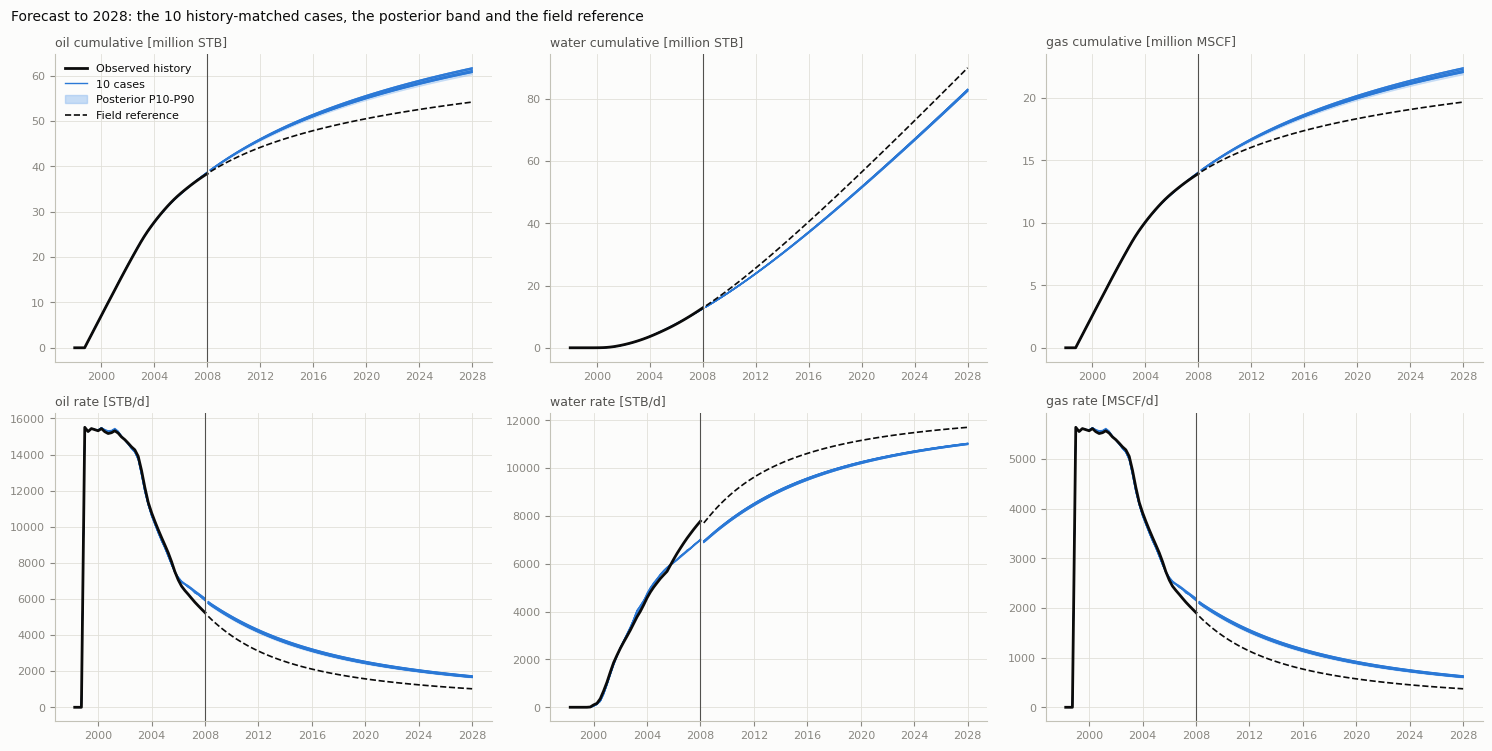

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.6))
FDATES = pd.DatetimeIndex(FD["date"])
for col, (j, ph) in enumerate([(OIL, "oil"), (WATER, "water"), (GAS, "gas")]):
    ax = _ax(axes[0, col])
    P = pct(FP)
    ax.fill_between(FDATES, P[0, :, j] / 1e6, P[2, :, j] / 1e6, color=BLUE_250, alpha=0.45, lw=0)
    for i in range(10):
        ax.plot(DATES, C10[i, :, j] / 1e6, color=BLUE_450, lw=0.8, alpha=0.8)
        ax.plot(FDATES, FC[i, :, j] / 1e6, color=BLUE_450, lw=0.9, alpha=0.9)
    ax.plot(FDATES, FIELD_REF[:, j] / 1e6, color=INK, lw=1.2, ls="--")
    ax.plot(DATES, YH[:, j] / 1e6, color=INK, lw=2)
    ax.axvline(DATES[-1], color=INK2, lw=0.8)
    ax.set_title(f"{ph} cumulative [million {'MSCF' if ph == 'gas' else 'STB'}]", loc="left", fontsize=9, color=INK2)
    ax = _ax(axes[1, col])
    QP = np.diff(np.concatenate([CP[:, -1:, :], FP], axis=1), axis=1) / np.diff(np.r_[T[-1], T_OUT])[None, :, None]
    P = pct(QP)
    ax.fill_between(FDATES, P[0, :, j], P[2, :, j], color=BLUE_250, alpha=0.45, lw=0)
    for i in range(10):
        ax.plot(DATES[1:], Q10[i, 1:, j], color=BLUE_450, lw=0.8, alpha=0.8)
        ax.plot(FDATES, FQ[i, :, j], color=BLUE_450, lw=0.9, alpha=0.9)
    ax.plot(DATES[1:], QH[1:, j], color=INK, lw=2)
    QF = np.diff(np.r_[YH[-1, j], FIELD_REF[:, j]]) / np.diff(np.r_[T[-1], T_OUT])
    ax.plot(FDATES, QF, color=INK, lw=1.2, ls="--")
    ax.axvline(DATES[-1], color=INK2, lw=0.8)
    ax.set_title(f"{ph} rate [{'MSCF' if ph == 'gas' else 'STB'}/d]", loc="left", fontsize=9, color=INK2)
axes[0, 0].legend(handles=[Line2D([], [], color=INK, lw=2, label="Observed history"), Line2D([], [], color=BLUE_450, lw=1, label="10 cases"),
                           Patch(color=BLUE_250, alpha=0.45, label="Posterior P10-P90"), Line2D([], [], color=INK, lw=1.2, ls="--", label="Field reference")],
                  frameon=False, fontsize=8, loc="upper left")
_finish(fig, "forecast_fan", "Forecast to 2028: the 10 history-matched cases, the posterior band and the field reference")

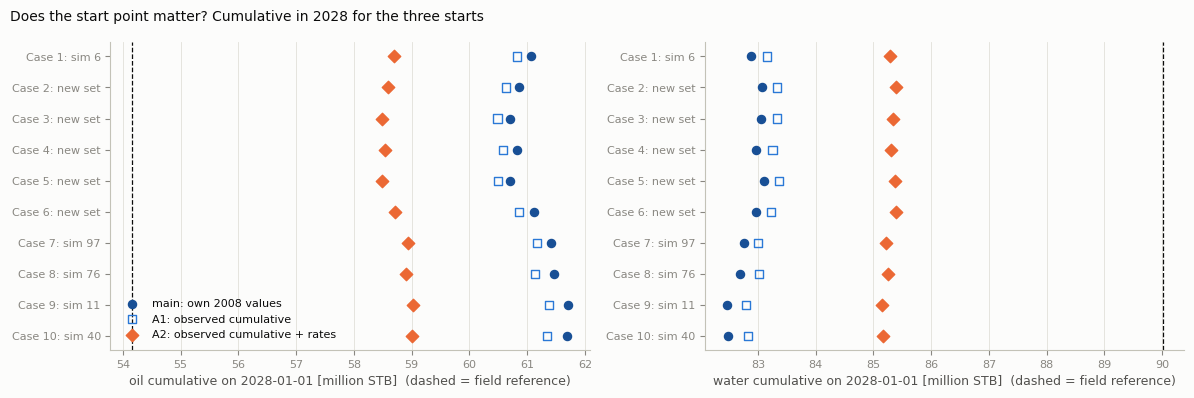

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax_, (j, ph) in zip(axes, [(OIL, "oil"), (WATER, "water")]):
    ax = _ax(ax_)
    y = np.arange(10)[::-1]
    ax.scatter(FC[:, -1, j] / 1e6, y, s=34, color=BLUE_600, label="main: own 2008 values", zorder=3)
    ax.scatter(FC_A1[:, -1, j] / 1e6, y, s=34, marker="s", facecolors="none", edgecolors=BLUE_450, label="A1: observed cumulative")
    ax.scatter(FC_A2[:, -1, j] / 1e6, y, s=40, marker="D", color=ORANGE, label="A2: observed cumulative + rates")
    ax.axvline(FIELD_REF[-1, j] / 1e6, color=INK, lw=0.9, ls="--")
    ax.set_yticks(y); ax.set_yticklabels(LABELS, fontsize=8)
    ax.set_xlabel(f"{ph} cumulative on 2028-01-01 [million STB]  (dashed = field reference)")
    ax.grid(axis="y", visible=False)
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
_finish(fig, "alternative_start", "Does the start point matter? Cumulative in 2028 for the three starts")

## 7. Deliverable: the 09 template

`dataset_ori/09 Template Deliverable.xlsx` has 10 sheets (`Case 1` to `Case 10`), each with the columns **Date**, **Gas production cumulative [MSCF]**, **Oil production cumulative [STB]**, **Water production cumulative [STB]** and 80 quarterly rows (04/01/2008 to 01/01/2028). The template is copied, the value columns are filled with the main forecast (sheet `Case k` = history-matching rank k), and the Date column is left as it is. The file is read back and checked.

In [11]:
from openpyxl import load_workbook


def write_deliverable(F, out_path, template=TEMPLATE):
    wb = load_workbook(template)
    for k in range(10):
        ws = wb[f"Case {k + 1}"]
        assert ws.cell(1, 2).value.startswith("Gas") and ws.cell(1, 3).value.startswith("Oil") and ws.cell(1, 4).value.startswith("Water")
        for r in range(80):
            for col, j in [(2, GAS), (3, OIL), (4, WATER)]:
                cell = ws.cell(row=2 + r, column=col, value=float(np.round(F[k, r, j], 0)))
                cell.number_format = "0"
    wb.save(out_path)


write_deliverable(FC, DELIVERABLE)
report = {}
for k in range(10):
    name = f"Case {k + 1}"
    tpl = pd.read_excel(TEMPLATE, sheet_name=name, header=None)
    out = pd.read_excel(DELIVERABLE, sheet_name=name, header=None)
    vals = np.asarray(out.iloc[1:81, 1:4], dtype=float)
    report[name] = {
        "rows": int(vals.shape[0]),
        "dates_match_template": bool((tpl.iloc[:, 0].astype(str).to_numpy() == out.iloc[:, 0].astype(str).to_numpy()).all()),
        "headers_match": bool((tpl.iloc[0, :4].astype(str).to_numpy() == out.iloc[0, :4].astype(str).to_numpy()).all()),
        "finite": bool(np.isfinite(vals).all()),
        "monotone": bool((np.diff(vals, axis=0) >= -1e-6).all()),
        "continuous_with_2008": bool((vals[0] >= np.round(C10[k, -1, [GAS, OIL, WATER]]) - 1).all()),
        "matches_forecast": bool(np.allclose(vals, np.round(FC[k][:, [GAS, OIL, WATER]]), atol=0.5)),
    }
REP = pd.DataFrame(report).T
print(REP.to_string())
assert (REP.drop(columns="rows").all().all()) and (REP["rows"] == 80).all(), "deliverable validation failed"
print(f"\nwrote and validated {DELIVERABLE}")

        rows dates_match_template headers_match finite monotone continuous_with_2008 matches_forecast
Case 1    80                 True          True   True     True                 True             True
Case 2    80                 True          True   True     True                 True             True
Case 3    80                 True          True   True     True                 True             True
Case 4    80                 True          True   True     True                 True             True
Case 5    80                 True          True   True     True                 True             True
Case 6    80                 True          True   True     True                 True             True
Case 7    80                 True          True   True     True                 True             True
Case 8    80                 True          True   True     True                 True             True
Case 9    80                 True          True   True     True                 Tr

In [12]:
# Long table for Power BI and the slides: history and forecast, every case, rates and cumulatives
rows = []
for i in range(10):
    hist_q = Q10[i]
    for k in range(len(T)):
        for j, ph in [(OIL, "oil"), (GAS, "gas"), (WATER, "water")]:
            rows.append((int(TOP["rank"][i]), LABELS[i], str(DATES[k].date()), "history (case)", ph, C10[i, k, j], hist_q[k, j]))
    for k in range(80):
        for j, ph in [(OIL, "oil"), (GAS, "gas"), (WATER, "water")]:
            rows.append((int(TOP["rank"][i]), LABELS[i], str(FDATES[k].date()), "forecast", ph, FC[i, k, j], FQ[i, k, j]))
for k in range(len(T)):
    for j, ph in [(OIL, "oil"), (GAS, "gas"), (WATER, "water")]:
        rows.append((0, "Observed field", str(DATES[k].date()), "history (observed)", ph, YH[k, j], QH[k, j]))
LONG = pd.DataFrame(rows, columns=["rank", "case", "date", "period", "phase", "cumulative", "rate_per_day"])
LONG.to_csv(FC_DIR / "forecast_cases_long.csv", index=False)
summary = {"final_method": FINAL_NAME, "ensemble": USE_ENSEMBLE, "injection_after_2008": INJ_FUTURE,
           "backtest_best": BEST.round(4).to_dict(orient="records"), "checks": checks,
           "oil_2028_MM": {"P10": float(np.percentile(FC[:, -1, OIL], 10) / 1e6), "mean": float(FC[:, -1, OIL].mean() / 1e6),
                           "P90": float(np.percentile(FC[:, -1, OIL], 90) / 1e6)},
           "field_reference_2028_MM": {"oil": float(FIELD_REF[-1, OIL] / 1e6), "water": float(FIELD_REF[-1, WATER] / 1e6)},
           "deliverable": str(DELIVERABLE.relative_to(ROOT))}
(FC_DIR / "forecast_run_summary.json").write_text(json.dumps(summary, indent=2, default=float))
print("saved to", FC_DIR)
for f in sorted(FC_DIR.glob("*.*")):
    print(f"  {f.name:<40} {f.stat().st_size / 1e3:>9.1f} kB")

saved to C:\Users\Yi Siang\Documents\UM\dwc_team_what_repo\forecast_output
  10_Final_deliverables.xlsx                    40.0 kB
  alternative_start_comparison.csv               1.0 kB
  backtest_all_settings.csv                      8.3 kB
  backtest_best_per_method.csv                   0.8 kB
  forecast_bands.csv                            66.3 kB
  forecast_cases_long.csv                      299.6 kB
  forecast_run_summary.json                      1.8 kB
  forecast_summary_by_case.csv                   1.5 kB


## 8. Conclusions

The numbers are printed above and collected in `forecast_output/forecast_run_summary.json`; the method choices and their sources are in `forecast_summary.md`.

**Limits.** The backtest covers at most 12 quarters; the forecast covers 80. It is evidence for the method, not a proof of the 20-year accuracy. The forecast assumes constant water injection, no new wells and no change of operating conditions after 2008.